# Document Detection with YOLOv5 Instance Segmentation Model with 200 Epochs

In [ ]:
!nvidia-smi

Wed Oct 22 07:20:55 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Install YOLOv5

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


In [ ]:
%cd /content
!git clone https://github.com/ultralytics/yolov5

/content
Cloning into 'yolov5'...
remote: Enumerating objects: 17611, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 17611 (delta 8), reused 2 (delta 2), pack-reused 17595 (from 3)
Receiving objects: 100% (17611/17611), 16.89 MiB | 16.97 MiB/s, done.
Resolving deltas: 100% (11987/11987), done.


In [ ]:
%cd /content/yolov5
!pip install -r requirements.txt
!pip uninstall wandb -qy
import torch

from IPython.display import Image, clear_output

print('Setup complete. Using torch %s %s' % (torch.__version__, torch.cuda.get_device_properties(0) if torch.cuda.is_available() else 'CPU'))

/content/yolov5
Setup complete. Using torch 2.9.0+cu126 _CudaDeviceProperties(name='Tesla T4', major=7, minor=5, total_memory=15095MB, multi_processor_count=40, uuid=f829e9cf-2f6d-e92b-30cd-aed145c5be64, pci_bus_id=0, pci_device_id=4, pci_domain_id=0, L2_cache_size=4MB)


In [ ]:
%cd /content/yolov5
!pip install -q roboflow==1.1.48 -q

!pip install roboflow

from roboflow import Roboflow

# Load Dataset

/content/yolov5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 24.9 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...


## Train On Custom Data

In [ ]:
%cd {HOME}/yolov5
!python segment/train.py \
  --img 640 \
  --batch -1 \
  --epochs 200 \
  --data {dataset.location}/data.yaml \
  --weights yolov5s-seg.pt \
  --name custom-dataset \
  --cache

Streaming output truncated to the last 5000 lines.
     93/199      9.83G    0.01896   0.007677   0.009106          0         89        640:  90% 19/21 [00:12<00:01,  1.61it/s]/content/yolov5/segment/train.py:385: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
     93/199      9.83G    0.01935   0.007688     0.0091          0         81        640:  95% 20/21 [00:13<00:00,  1.57it/s]/content/yolov5/segment/train.py:385: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
     93/199      9.83G    0.01978   0.007802   0.009147          0         28        640: 100% 21/21 [00:13<00:00,  1.58it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% 2/2 [00:01<00:00,  1.97it/s]
         

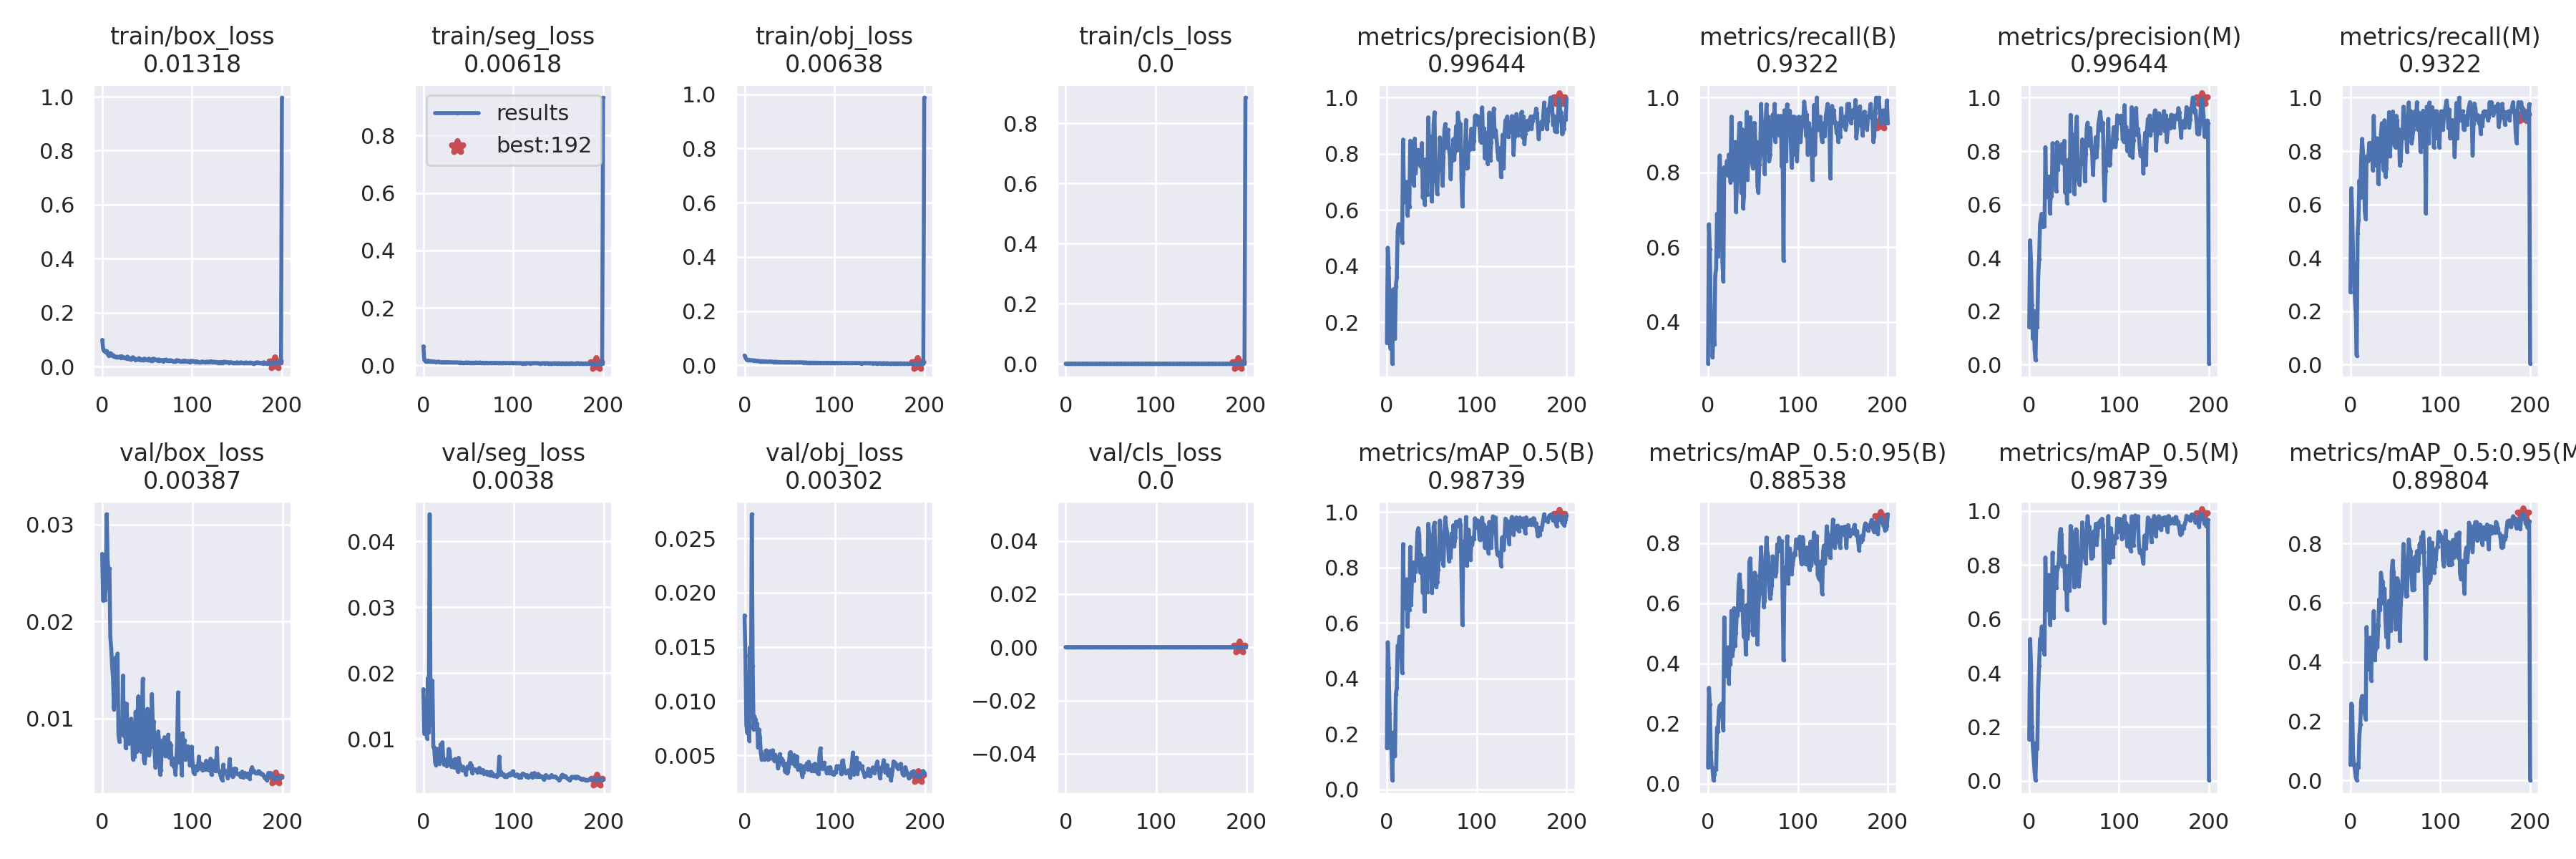

In [ ]:
Image(filename=f'{HOME}/yolov5/runs/train-seg/custom-dataset/results.png', width=1200)

## Validate Custom Model

In [ ]:
%cd {HOME}/yolov5
!python segment/val.py \
  --weights {HOME}/yolov5/runs/train-seg/custom-dataset/weights/best.pt \
  --data {dataset.location}/data.yaml \
  --img 640 \
  --iou-thres 0.75 \
  --name custom-dataset

/content/yolov5
segment/val: data=/content/yolov5/document_detection-9/data.yaml, weights=['/content/yolov5/runs/train-seg/custom-dataset/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.75, max_det=300, task=val, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val-seg, name=custom-dataset, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-441-g15c0127a Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)

Fusing layers... 
Model summary: 165 layers, 7398422 parameters, 0 gradients, 25.7 GFLOPs
val: Scanning /content/yolov5/document_detection-9/valid/labels.cache... 59 images, 0 backgrounds, 0 corrupt: 100% 59/59 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% 2/2 [00:03<00:00,  1.55s/it]
                   all         59         59      0.996 

## Infer With Custom Model

/content/yolov5
segment/predict: weights=['/content/yolov5/runs/train-seg/custom-dataset/weights/best.pt'], source=/content/yolov5/document_detection-9/test/images/image_532_jpg.rf.43f2f45ca4c7a7b31231a8b8569c9b0d.jpg, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.75, max_det=1000, device=, view_img=False, save_txt=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/predict-seg, name=custom-dataset, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1, retina_masks=False
YOLOv5 🚀 v7.0-441-g15c0127a Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)

Fusing layers... 
Model summary: 165 layers, 7398422 parameters, 0 gradients, 25.7 GFLOPs
image 1/1 /content/yolov5/document_detection-9/test/images/image_532_jpg.rf.43f2f45ca4c7a7b31231a8b8569c9b0d.jpg: 640x640 1 documents, 14.3ms
Speed: 0.6ms pre-process, 14

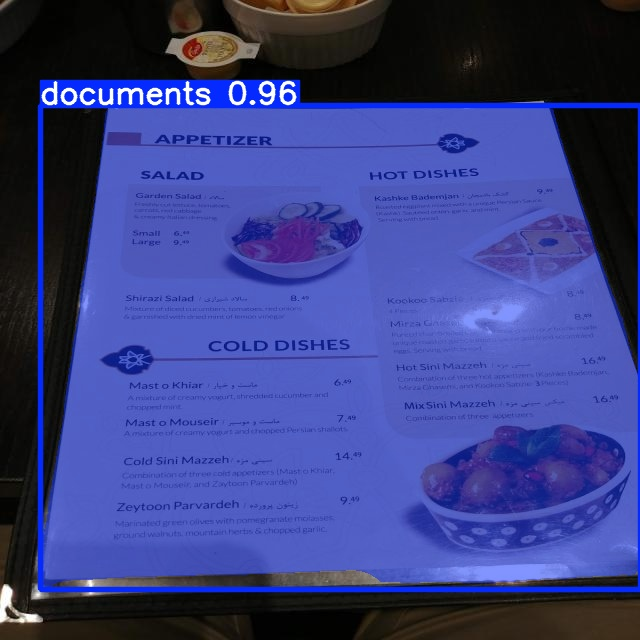

In [ ]:
import os

if os.path.exists(os.path.join(dataset.location, "test")):
    split_path = os.path.join(dataset.location, "test", "images")
else:
    split_path = os.path.join(dataset.location, "valid", "images")
example_image_name = os.listdir(split_path)[3]
example_image_path = os.path.join(split_path, example_image_name)

%cd {HOME}/yolov5
!python segment/predict.py \
  --img 640 \
  --weights {HOME}/yolov5/runs/train-seg/custom-dataset/weights/best.pt \
  --source {example_image_path} \
  --iou-thres 0.75 \
  --name custom-dataset
Image(filename=f"{HOME}/yolov5/runs/predict-seg/custom-dataset/{example_image_name}", width=600)

In [ ]:
!zip -r /content/yolov5.zip /content/yolov5

  adding: content/yolov5/ (stored 0%)
  adding: content/yolov5/CITATION.cff (deflated 31%)
  adding: content/yolov5/.git/ (stored 0%)
  adding: content/yolov5/.git/config (deflated 33%)
  adding: content/yolov5/.git/branches/ (stored 0%)
  adding: content/yolov5/.git/info/ (stored 0%)
  adding: content/yolov5/.git/info/exclude (deflated 28%)
  adding: content/yolov5/.git/refs/ (stored 0%)
  adding: content/yolov5/.git/refs/remotes/ (stored 0%)
  adding: content/yolov5/.git/refs/remotes/origin/ (stored 0%)
  adding: content/yolov5/.git/refs/remotes/origin/HEAD (stored 0%)
  adding: content/yolov5/.git/refs/tags/ (stored 0%)
  adding: content/yolov5/.git/refs/heads/ (stored 0%)
  adding: content/yolov5/.git/refs/heads/master (stored 0%)
  adding: content/yolov5/.git/packed-refs (deflated 48%)
  adding: content/yolov5/.git/description (deflated 14%)
  adding: content/yolov5/.git/index (deflated 55%)
  adding: content/yolov5/.git/HEAD (stored 0%)
  adding: content/yolov5/.git/FETCH_HEAD (d